In [10]:
#import corner
import numpy as np
import random
import pandas as pd
from scipy.integrate import odeint
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib import dates
from sklearn.metrics import mean_squared_error, r2_score
from datetime import datetime
#from lmfit import Minimizer, Parameters, Parameter, report_fit, printfuncs, conf_interval,minimize
from lmfit import Parameters, Parameter
from statsmodels.tsa.arima_model import ARIMA

from scipy.optimize import minimize
from scipy.stats import binom
import scipy.stats as stats

#import numdifftools as ndt
import statsmodels.api as sm

from utils import *

%matplotlib inline



# step 0: data importation #

In [7]:
csv_url="https://raw.githubusercontent.com/ADelau/proj0016-epidemic-data/main/data.csv"
data = pd.read_csv(csv_url)
data['day_hospitalization']=data['num_cumulative_hospitalizations'].diff().shift(periods=-1)

In [8]:
data.head()

,Day,num_positive,num_tested,num_hospitalised,num_cumulative_hospitalizations,num_critical,num_fatalities,day_hospitalization
0,1,0,0,1,1,0,0,0.0
1,2,5,8,1,1,0,0,1.0
2,3,10,12,2,2,0,0,0.0
3,4,11,16,2,2,0,0,0.0
4,5,9,12,2,2,0,0,0.0


In [9]:
data4col=csv2numpy(csv_url)

NameError: name 'np' is not defined

# step 1: setting up the model #

In [ ]:
def guessp():
    p=np.array([1e6-50,50,50,50,0,0,0,0.2,0.33,0.4,0.1,0.1,0.12,0.1,0.1,0.08,0.08,0.8])
    return p

In [5]:
params = Parameters()
params.add('E0',value=50, min=5, max=300)
params.add('I0',value=50, min=5, max=300)
params.add('C0',value=50, min=5, max=300)
params.add('S0',vary=False,value=1e6-params['E0']-params['I0']-params['C0'], min=1e6-3000, max=1e6-10)
params.add('H0',vary=False, value=1,min=0,max=1)
params.add('ICU0', vary=False, value=0,min=0,max=1)
params.add('D0', vary=False, value=0,min=0,max=1)
params.add('coeff_SE',value=0.1,min=0.01,max=0.8)
params.add('coeff_Esortant',value=0.1,min=0.01,max=10)
params.add('ratio_EC_Esortant',value=0.4,min=0.3,max=0.9)
params.add('coeff_Isortant',value=0.1,min=0.01,max=1)
params.add('ratio_IH_Isortant',value=0.05,min=0.0001,max=0.5)
params.add('coeff_Hsortant',value=0.1,min=0.01,max=1)
params.add('ratio_H_ICU_Hsortant',value=0.1,min=0.01,max=1)
params.add('coeff_CR',value=0.1,min=0.01,max=1)
params.add('coeff_ICUsortant',value=0.1,min=0.01,max=0.5)
params.add('ratio_ICUD_ICUsortant',value=0.05,min=0.001,max=0.1)
params.add('ratio_nbpositifs_EI',value=0.16,min=0.05,max=0.3)

In [85]:
def test(**option):
    if option["choix"] == 'D':
        return 1


def test2(**option):
    return test(**option)

test(choix='D')

1

In [36]:
#negative log likelihood
def LMAIN(data_obs,data_sim,p):
    
    comp1=binomloglike(data_obs[:,0],data_sim[0][:,2],np.divide(data_sim[2][:,1]*p[17],nozero(data_sim[0][:,2])))
    comp2=binomloglike(data_obs[:,1],data_sim[0][:,2],np.divide(data_sim[2][:,3]*p[10]*p[11],nozero(data_sim[0][:,2])))
    comp3=binomloglike(data_obs[:,2],data_sim[0][:,4],np.divide(data_sim[2][:,4]*p[12]*p[13],nozero(data_sim[0][:,4])))
    comp4=binomloglike(data_obs[:,3],data_sim[0][:,5],np.divide(data_sim[2][:,5]*p[15]*p[16],nozero(data_sim[0][:,5])))
    return comp1,comp2,comp3,comp4

In [391]:
def transitions(y,params,**option):
    
    result=np.zeros(10)  
    
    if option["choix"] == 'D':
        # transisitons array ['S_E', 'E_I', 'E_C','I_H','H_ICU','ICU_D','C_R','I_R','H_R','ICU_R']
        result[0] =  (y[2]+y[3])*params['coeff_SE']*y[0]/(1e6-y[6])
        result[1] =  y[1]*params['coeff_Esortant']*(1-params['ratio_EC_Esortant'])
        result[2] = y[1]*params['coeff_Esortant']*params['ratio_EC_Esortant']
        result[3] = y[3]*params['coeff_Isortant']*params['ratio_IH_Isortant']
        result[4] = y[4]*params['coeff_Hsortant']*params['ratio_H_ICU_Hsortant']
        result[5] = y[5]*params['coeff_ICUsortant']*params['ratio_ICUD_ICUsortant']
        result[6] = y[2]*params['coeff_CR']
        result[7] = y[3]*params['coeff_Isortant']*(1-params['ratio_IH_Isortant'])
        result[8] = y[4]*params['coeff_Hsortant']*(1-params['ratio_ICUD_ICUsortant'])
        result[9] = y[5]*params['coeff_ICUsortant']*(1-params['ratio_ICUD_ICUsortant'])
    
    if option["choix"] =='P':
        result[0] =  (y[2]+y[3])*params['coeff_SE']*y[0]/(1e6-y[6])
        
    
    return result

In [395]:
y0=np.array([1e6-200,50,50,100,0,0,0])
transitions(y0,params,choix='D')

array([14.997,  3.   ,  2.   ,  0.5  ,  0.   ,  0.   ,  5.   ,  9.5  ,
        0.   ,  0.   ])

In [212]:
def deriv(y, params,**option):
    TR=transitions(y,params,**option)
   # transisitons array ['S_E', 'E_I', 'E_C','I_H','H_ICU','ICU_D','C_R','I_R','H_R','ICU_R']
    
    dS = -TR[0]
    dE = TR[0] - TR[1] - TR[2]
    dI = TR[1] - TR[7]  - TR[3]
    dC = TR[2] - TR[6]
    dH = TR[3] - TR[4] - TR[8]
    dICU = TR[4] - TR[5] - TR[9]
    dD = TR[5]
    
    return np.array([dS, dE, dI, dC, dH, dICU, dD]), TR

In [12]:
def fullsim(params,nbdays,**option):

  
    dpop = np.zeros((nbdays,7))
    pop = np.zeros((nbdays,7))
    historique_transition = np.zeros((nbdays,10))
    
    
    pop[0]=np.array([params['S0'].value,params['E0'].value,params['I0'].value,params['C0'].value,
                     params['H0'].value,params['ICU0'].value,params['D0'].value])
    
    dpop[0],historique_transition[0]=deriv(pop[0],params,**option)

    for i in range(1,nbdays):
        pop[i]=pop[i-1]+dpop[i-1]
        dpop[i],historique_transition[i]=deriv(pop[i], params,**option)
    
    return pop, dpop, historique_transition

# fitting the deterministic model (with random test observations) #

In [215]:
#p=['S_E', 'E_I', 'E_C','I_H','H_ICU','ICU_D','C_R','I_R','H_R','ICU_R','Sensitiviy','S0','E0','I0','C0','H0','ICU0','D0']
def model_obs(params,nbdays,**option):
    result = np.zeros((nbdays,4))
    pop, dpop, historique_transition=fullsim(params,nbdays,**option)
    
    if option['choix']=='D':
        for i in range (0,nbdays):
            result[i][0]=np.random.binomial(historique_transition[i][1],params['ratio_nbpositifs_EI'].value)
            result[i][1]=pop[i][4]
            result[i][2]=pop[i][5]
            result[i][3]=pop[i][6]
    return result
    
    

In [101]:
y_sim=model_obs(params,71, choix ='D')


In [199]:

def residual(params,data):
    sim=model_obs(params,71,choix='D')
    residual_array=sim.flatten()-data.flatten()
    #return residual_array
    return residual_array[~(np.isnan(residual_array))] 

In [161]:
mini_nelder = Minimizer(residual, params,(data4col,))
result_nelder = mini.minimize(method='nelder')

In [201]:
#mini_newton = Minimizer(residual, params,(data4col,))
#result_newton = mini.minimize(method='newton')

In [163]:
fit_nelder= model_obs(result_nelder.params,71,choix='D')


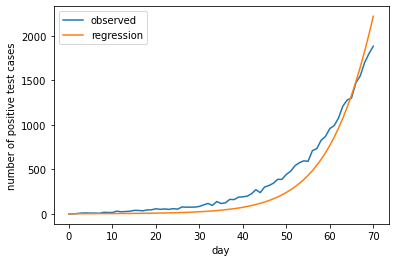

In [225]:
fig = plt.figure()



plt.plot(data4col[:,0],label='observed')
plt.plot(fit_nelder[:,0],label='regression')
plt.xlabel('day')
plt.ylabel('number of positive test cases')
plt.legend()
plt.show
plt.savefig('nelder_infections.png')

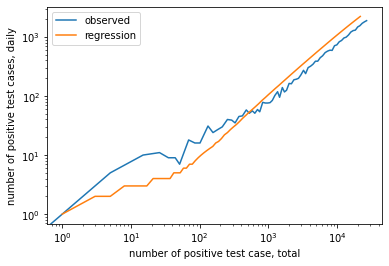

In [226]:
fig = plt.figure()

plt.loglog(data4col[:,0].cumsum(),data4col[:,0],label='observed')
plt.loglog(fit_nelder[:,0].cumsum(),fit_nelder[:,0],label='regression')
plt.xlabel('number of positive test case, total')
plt.ylabel('number of positive test cases, daily')
plt.legend()
plt.show
plt.savefig('nelder_dI_I.png')

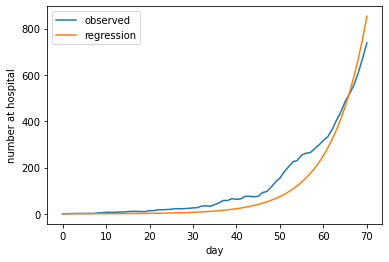

In [227]:


fig = plt.figure()

plt.plot(data4col[:,1],label='observed')
plt.plot(fit_nelder[:,1],label='regression')
plt.xlabel('day')
plt.ylabel('number at hospital')
plt.legend()
plt.show
plt.savefig('nelder_H.png')

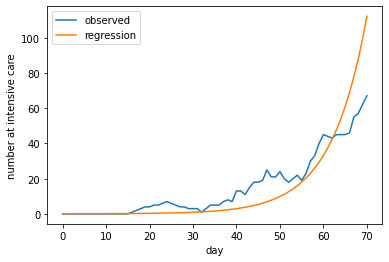

In [228]:
fig = plt.figure()

plt.plot(data4col[:,2],label='observed')
plt.plot(fit_nelder[:,2],label='regression')
plt.xlabel('day')
plt.ylabel('number at intensive care')
plt.legend()
plt.show
plt.savefig('nelder_ICU.png')

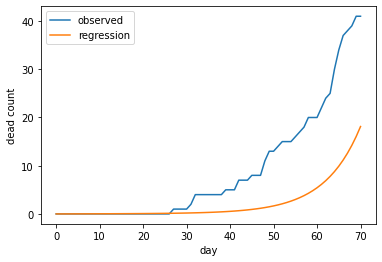

In [229]:
fig = plt.figure()

plt.plot(data4col[:,3],label='observed')
plt.plot(fit_nelder[:,3],label='regression')
plt.xlabel('day')
plt.ylabel('dead count')
plt.legend()
plt.show
plt.savefig('nelder_D.png')

### MLE with a deterministic model ###

In [11]:
fullsim(params,71,choix='D')

NameError: name 'fullsim' is not defined

In [345]:
#negative log likelihood!
def binomloglike(y_obs,params):
    resultat=0

    n_array=fullsim(params,71,choix='D')[2][:,1]
    
    for t in range(y_obs.shape[0]):
        resultat=resultat-binom.logpmf(y_obs[t], np.round(n_array[t]), params['ratio_nbpositifs_EI'].value)
        print(y_obs[t],n_array[t])
    return resultat

In [398]:
dict=result_nelder.params

In [415]:
dict.valuesdict().values()

odict_values([35.155444208103546, 6.598748835720931, 260.8242594123801, 999850.0, 1, 0, 0, 0.1227812308660381, 0.2926738367923275, 0.3906245646232661, 0.08524708071033611, 0.0058349364494743785, 0.0962702628788136, 0.7557431307151162, 0.25636448860738376, 0.42319532396382026, 0.04922982372552547, 0.18737992049709729])

In [419]:
array_param=np.zeros(18)
array_param=np.array(list(dict.valuesdict().values()))

array([3.51554442e+01, 6.59874884e+00, 2.60824259e+02, 9.99850000e+05,
       1.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.22781231e-01,
       2.92673837e-01, 3.90624565e-01, 8.52470807e-02, 5.83493645e-03,
       9.62702629e-02, 7.55743131e-01, 2.56364489e-01, 4.23195324e-01,
       4.92298237e-02, 1.87379920e-01])

In [420]:
def binomloglike2(x,y_obs):
    
    
    params = Parameters()
    params.add('E0',value=x[0], min=5, max=300)
    params.add('I0',value=x[1], min=5, max=300)
    params.add('C0',value=x[2], min=5, max=300)
    params.add('S0',vary=False,value=1e6-params['E0']-params['I0']-params['C0'], min=1e6-3000, max=1e6-10)
    params.add('H0',vary=False, value=x[4],min=0,max=1)
    params.add('ICU0', vary=False, value=x[5],min=0,max=1)
    params.add('D0', vary=False, value=x[6],min=0,max=1)
    params.add('coeff_SE',value=x[7],min=0.01,max=0.8)
    params.add('coeff_Esortant',x[8],min=0.01,max=10)
    params.add('ratio_EC_Esortant',value=x[9],min=0.3,max=0.9)
    params.add('coeff_Isortant',value=x[10],min=0.01,max=1)
    params.add('ratio_IH_Isortant',value=x[11],min=0.0001,max=0.5)
    params.add('coeff_Hsortant',value=x[12],min=0.01,max=1)
    params.add('ratio_H_ICU_Hsortant',value=x[13],min=0.01,max=1)
    params.add('coeff_CR',value=x[14],min=0.01,max=1)
    params.add('coeff_ICUsortant',value=x[15],min=0.01,max=0.5)
    params.add('ratio_ICUD_ICUsortant',value=x[16],min=0.001,max=0.1)
    params.add('ratio_nbpositifs_EI',value=x[17],min=0.05,max=0.3)

    
    resultat=0

    n_array=fullsim(params,71,choix='D')[2][:,1]
    
    for t in range(y_obs.shape[0]):
        resultat=resultat-binom.logpmf(y_obs[t], np.round(n_array[t]), params['ratio_nbpositifs_EI'].value)
        print(y_obs[t],n_array[t])
    return resultat

In [ ]:
minimize(binomloglike2, array_param,(data4col[:,1]), method='nelder-mead')

0.0 0.034999999999999996
1.0 0.0353499895
1.0 0.035692979087851046
2.0 0.03602910876160716
2.0 0.036358515719349616
2.0 0.03668133441518683
2.0 0.036997696614134316
2.0 0.037307731445896976
4.0 0.037611565457575755
5.0 0.037909322665320135
7.0 0.03820112460494753
7.0 0.038487090381550376
7.0 0.03876733671811092
8.0 0.03904197800314383
8.0 0.03931112633738587
10.0 0.039574891579551824
11.0 0.039833381391175156
11.0 0.04008670128055203
10.0 0.0403349546458063
10.0 0.04057824281709327
14.0 0.04081666509795929
14.0 0.041050318805874224
18.0 0.04127929931195322
18.0 0.041503700079884034
19.0 0.04172361270407583
20.0 0.04193912694704494
23.0 0.042150330776052965
22.0 0.04235731039901203
23.0 0.04256015029967203
24.0 0.04275893327210399
26.0 0.04295374045449389
27.0 0.04314465136226051
34.0 0.043331743920510916
35.0 0.04351509449584689
33.0 0.04369477792753517
40.0 0.04387086755805432
48.0 0.04404343526303061
58.0 0.0442125514805752
58.0 0.04437828524003459
66.0 0.04454070419016602
63.0 0.044

182.0 0.046254032417475915
204.0 0.04637893464259162
225.0 0.04650133868321931
231.0 0.046621294502621514
254.0 0.046738851064794563
262.0 0.04685405635445409
265.0 0.046966957396620615
282.0 0.04707760027581355
298.0 0.047186030154861267
317.0 0.04729229129333496
333.0 0.04739642706561384
364.0 0.047498479978589025
404.0 0.04759849168901335
439.0 0.04769650302050419
485.0 0.047792553980206175
518.0 0.047886683775120696
555.0 0.04797893082810883
608.0 0.04806933279357418
671.0 0.04815792657283202
738.0 0.048244748329171125
0.0 0.034999999999999996
1.0 0.035349989500175
1.0 0.035692979088198414
2.0 0.03602910876212435
2.0 0.0363585157200341
2.0 0.036681334416036174
2.0 0.03699769661514613
2.0 0.03730773144706893
4.0 0.037611565458905566
5.0 0.03790932266680558
7.0 0.038201124606586444
7.0 0.038487090383340625
7.0 0.038767336720050435
8.0 0.03904197800523059
8.0 0.03931112633961792
10.0 0.03957489158192721
11.0 0.039833381393692
11.0 0.04008670128320848
10.0 0.04033495464860058
10.0 0.04

0.0 0.034999999999999996
1.0 0.0353499895
1.0 0.035692979087851046
2.0 0.03602910876160716
2.0 0.036358515719349616
2.0 0.03668133441518683
2.0 0.036997696614134316
2.0 0.037307731445896976
4.0 0.037611565457575755
5.0 0.037909322665320135
7.0 0.03820112460494753
7.0 0.038487090381550376
7.0 0.03876733671811092
8.0 0.03904197800314383
8.0 0.03931112633738587
10.0 0.039574891579551824
11.0 0.039833381391175156
11.0 0.04008670128055203
10.0 0.0403349546458063
10.0 0.04057824281709327
14.0 0.04081666509795929
14.0 0.041050318805874224
18.0 0.04127929931195322
18.0 0.041503700079884034
19.0 0.04172361270407583
20.0 0.04193912694704494
23.0 0.042150330776052965
22.0 0.04235731039901203
23.0 0.04256015029967203
24.0 0.04275893327210399
26.0 0.04295374045449389
27.0 0.04314465136226051
34.0 0.043331743920510916
35.0 0.04351509449584689
33.0 0.04369477792753517
40.0 0.04387086755805432
48.0 0.04404343526303061
58.0 0.0442125514805752
58.0 0.04437828524003459
66.0 0.04454070419016602
63.0 0.044

66.0 0.04454070419075953
63.0 0.044699874627354856
65.0 0.04485586152026422
76.0 0.04500872853995064
76.0 0.04515853808346597
74.0 0.04530535129991927
76.0 0.045449228115435766
92.0 0.045590227257616585
97.0 0.04572840627950936
116.0 0.04586382158309935
138.0 0.04599652844233083
155.0 0.04612658102566791
182.0 0.04625403241820427
204.0 0.046378934643330656
225.0 0.046501338683968954
231.0 0.04662129450338167
254.0 0.04673885106556515
262.0 0.04685405635523503
265.0 0.046966957397411815
282.0 0.04707760027661496
298.0 0.04718603015567279
317.0 0.04729229129415653
333.0 0.04739642706644538
364.0 0.047498479979430484
404.0 0.04759849168986466
439.0 0.047696503021365265
485.0 0.04779255398107696
518.0 0.047886683776001124
555.0 0.047978930828998845
608.0 0.04806933279447372
671.0 0.04815792657374103
738.0 0.04824474833008956
0.0 0.034999999999999996
1.0 0.03534998950000486
1.0 0.03569297908786069
2.0 0.03602910876162153
2.0 0.036358515719368635
2.0 0.036681334415210425
2.0 0.03699769661416

2.0 0.036358515719349616
2.0 0.03668133441518683
2.0 0.036997696614134316
2.0 0.037307731445896976
4.0 0.037611565457575755
5.0 0.037909322665320135
7.0 0.03820112460494753
7.0 0.038487090381550376
7.0 0.03876733671811092
8.0 0.03904197800314383
8.0 0.03931112633738587
10.0 0.039574891579551824
11.0 0.039833381391175156
11.0 0.04008670128055203
10.0 0.0403349546458063
10.0 0.04057824281709327
14.0 0.04081666509795929
14.0 0.041050318805874224
18.0 0.04127929931195322
18.0 0.041503700079884034
19.0 0.04172361270407583
20.0 0.04193912694704494
23.0 0.042150330776052965
22.0 0.04235731039901203
23.0 0.04256015029967203
24.0 0.04275893327210399
26.0 0.04295374045449389
27.0 0.04314465136226051
34.0 0.043331743920510916
35.0 0.04351509449584689
33.0 0.04369477792753517
40.0 0.04387086755805432
48.0 0.04404343526303061
58.0 0.0442125514805752
58.0 0.04437828524003459
66.0 0.04454070419016602
63.0 0.04469987462674941
65.0 0.04485586151964695
76.0 0.045008728539321655
76.0 0.04515853808282538


317.0 0.047292291293333066
333.0 0.047396427065611896
364.0 0.047498479978587034
404.0 0.04759849168901131
439.0 0.0476965030205021
485.0 0.047792553980204024
518.0 0.047886683775118496
555.0 0.047978930828106586
608.0 0.04806933279357188
671.0 0.04815792657282967
738.0 0.048244748329168724
0.0 0.034999999999999996
1.0 0.0353499895
1.0 0.035692979087851046
2.0 0.03602910876160716
2.0 0.036358515719349616
2.0 0.03668133441518683
2.0 0.036997696614134316
2.0 0.037307731445896976
4.0 0.037611565457575755
5.0 0.037909322665320135
7.0 0.03820112460494753
7.0 0.038487090381550376
7.0 0.03876733671811092
8.0 0.03904197800314383
8.0 0.03931112633738587
10.0 0.039574891579551824
11.0 0.039833381391175156
11.0 0.04008670128055203
10.0 0.0403349546458063
10.0 0.04057824281709327
14.0 0.04081666509795929
14.0 0.041050318805874224
18.0 0.04127929931195322
18.0 0.041503700079884034
19.0 0.04172361270407583
20.0 0.04193912694704494
23.0 0.042150330776052965
22.0 0.04235731039901203
23.0 0.04256015029

... (429 outputs left out)

404.0 0.04759849168901131
439.0 0.0476965030205021
485.0 0.047792553980204024
518.0 0.047886683775118496
555.0 0.047978930828106586
608.0 0.04806933279357188
671.0 0.04815792657282967
738.0 0.048244748329168724
0.0 0.034999999999999996
1.0 0.0353499895
1.0 0.035692979087851046
2.0 0.03602910876160716
2.0 0.036358515719349616
2.0 0.03668133441518683
2.0 0.036997696614134316
2.0 0.037307731445896976
4.0 0.037611565457575755
5.0 0.037909322665320135
7.0 0.03820112460494753
7.0 0.038487090381550376
7.0 0.03876733671811092
8.0 0.03904197800314383
8.0 0.03931112633738587
10.0 0.039574891579551824
11.0 0.039833381391175156
11.0 0.04008670128055203
10.0 0.0403349546458063
10.0 0.04057824281709327
14.0 0.04081666509795929
14.0 0.041050318805874224
18.0 0.04127929931195322
18.0 0.041503700079884034
19.0 0.04172361270407583
20.0 0.04193912694704494
23.0 0.042150330776052965
22.0 0.04235731039901203
23.0 0.04256015029967203
24.0 0.04275893327210399
26.0 0.04295374045449389
27.0 0.04314465136226051

298.0 0.047186030154859435
317.0 0.047292291293333066
333.0 0.047396427065611896
364.0 0.047498479978587034
404.0 0.04759849168901131
439.0 0.0476965030205021
485.0 0.047792553980204024
518.0 0.047886683775118496
555.0 0.047978930828106586
608.0 0.04806933279357188
671.0 0.04815792657282967
738.0 0.048244748329168724
0.0 0.034999999999999996
1.0 0.0353499895
1.0 0.035692979087851046
2.0 0.03602910876160716
2.0 0.036358515719349616
2.0 0.03668133441518683
2.0 0.036997696614134316
2.0 0.037307731445896976
4.0 0.037611565457575755
5.0 0.037909322665320135
7.0 0.03820112460494753
7.0 0.038487090381550376
7.0 0.03876733671811092
8.0 0.03904197800314383
8.0 0.03931112633738587
10.0 0.039574891579551824
11.0 0.039833381391175156
11.0 0.04008670128055203
10.0 0.0403349546458063
10.0 0.04057824281709327
14.0 0.04081666509795929
14.0 0.041050318805874224
18.0 0.04127929931195322
18.0 0.041503700079884034
19.0 0.04172361270407583
20.0 0.04193912694704494
23.0 0.042150330776052965
22.0 0.042357310

2.0 0.036997696614134316
2.0 0.037307731445896976
4.0 0.037611565457575755
5.0 0.037909322665320135
7.0 0.03820112460494753
7.0 0.038487090381550376
7.0 0.03876733671811092
8.0 0.03904197800314383
8.0 0.03931112633738587
10.0 0.039574891579551824
11.0 0.039833381391175156
11.0 0.04008670128055203
10.0 0.0403349546458063
10.0 0.04057824281709327
14.0 0.04081666509795929
14.0 0.041050318805874224
18.0 0.04127929931195322
18.0 0.041503700079884034
19.0 0.04172361270407583
20.0 0.04193912694704494
23.0 0.042150330776052965
22.0 0.04235731039901203
23.0 0.04256015029967203
24.0 0.04275893327210399
26.0 0.04295374045449389
27.0 0.04314465136226051
34.0 0.043331743920510916
35.0 0.04351509449584689
33.0 0.04369477792753517
40.0 0.04387086755805432
48.0 0.04404343526303061
58.0 0.0442125514805752
58.0 0.04437828524003459
66.0 0.04454070419016602
63.0 0.04469987462674941
65.0 0.04485586151964695
76.0 0.045008728539321655
76.0 0.04515853808282538
74.0 0.045305351299267174
76.0 0.0454492281147722

97.0 0.04572840627882338
116.0 0.04586382158240228
138.0 0.04599652844162275
155.0 0.04612658102494892
182.0 0.046254032417474465
204.0 0.04637893464259012
225.0 0.04650133868321778
231.0 0.04662129450261992
254.0 0.04673885106479292
262.0 0.046854056354452396
265.0 0.04696695739661887
282.0 0.047077600275811766
298.0 0.047186030154859435
317.0 0.047292291293333066
333.0 0.047396427065611896
364.0 0.047498479978587034
404.0 0.04759849168901131
439.0 0.0476965030205021
485.0 0.047792553980204024
518.0 0.047886683775118496
555.0 0.047978930828106586
608.0 0.04806933279357188
671.0 0.04815792657282967
738.0 0.048244748329168724
0.0 0.034999999999999996
1.0 0.0353499895
1.0 0.035692979087851046
2.0 0.03602910876160716
2.0 0.036358515719349616
2.0 0.03668133441518683
2.0 0.036997696614134316
2.0 0.037307731445896976
4.0 0.037611565457575755
5.0 0.037909322665320135
7.0 0.03820112460494753
7.0 0.038487090381550376
7.0 0.03876733671811092
8.0 0.03904197800314383
8.0 0.03931112633738587
10.0 0

In [35]:
def nozero(array):
    array=np.where(array==0, 1, array)
    return array
def forcepositive(array):
    array=np.where(array<0, 0, array)
    return array   

## OLS ##

In [365]:
res5.x

array([ 9.99950000e+05,  5.00000000e+01,  1.10023126e+02,  4.99999231e+01,
        2.93486815e-01,  6.49110589e+00,  8.90140845e+00,  1.83330060e-01,
        3.30000568e-01,  3.99996813e-01,  1.00002613e-01,  9.99988745e-02,
        1.20000000e-01,  9.99990991e-02, -1.10046212e+00,  8.00000000e-02,
        8.00000000e-02,  4.00000000e-02])

In [ ]:
def plotwave(df):
    y=df['num_positive']
    x=df['num_positive'].cumsum()
    plt.loglog(x,y)

In [ ]:
plotwave(sim_130);
plotwave(data)

In [ ]:
plt.plot(sim_70['num_critical'],label='sim');
plt.plot(data['num_critical'],label='data')


In [ ]:
verif1=data2comp(result.params,data)
verif2=params2comp(result.params,np.linspace(0,70,71))

In [ ]:
plt.plot(verif1['ICU'].cumsum());
plt.plot(verif2['ICU'].cumsum());

In [ ]:
verif2

### simulations ###